# Oscar — 02: logistic regression (working)

Scratch notebook for trying out logistic regression on the credit default data.
Uses the shared split made by `report/01-Data.ipynb`: **run that first**.

Only `train` and `validation` are loaded here. The test set is left alone until
the final model is chosen, so nothing in this notebook can be tuned on it.

In [5]:
import pandas as pd

import prep                         # Oscar/prep.py: loading and fixes 1-4 from 01-eda.ipynb

X_train, y_train = prep.load("train")
X_val, y_val = prep.load("validation")

for name, y in [("train", y_train), ("validation", y_val)]:
    print(f"{name:<10} {len(y):,} customers, {y.mean():.2%} defaulted")

train      17,997 customers, 22.12% defaulted
validation 5,999 customers, 22.12% defaulted


Apply fixes 1–4 from `01-eda.ipynb`: repayment status and demographics as
categories, signed log of the amounts, then standardise. Train goes first, because
the scaling is learned from train only.

In [6]:
X_train, X_val = prep.transform(X_train, X_val)

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
X_train.head()

X_train: (17997, 50)   X_val: (5999, 50)


,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,...,PAY_6_0,PAY_6_1,PAY_6_2,PAY_6_3,SEX_2,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3
ID,,,,,,,,,,,,,,,,,,,,,
1,-1.879492,-1.243785,-0.193659,-0.185340,-0.531585,-2.118182,-2.039339,-1.921369,-2.030296,-0.009352,...,-1.089993,0.0,-0.317704,-0.108657,0.805782,1.081006,-0.446184,-0.125028,-1.070311,-0.116012
2,0.029578,-1.027394,-0.300176,-0.339332,-0.184367,-0.091751,-0.034399,0.000874,-2.030296,0.104095,...,-1.089993,0.0,3.147582,-0.108657,0.805782,1.081006,-0.446184,-0.125028,0.934308,-0.116012
4,-0.903219,0.162760,0.507403,0.534969,0.559881,0.448487,0.488696,0.524477,0.301417,0.318173,...,0.917437,0.0,-0.317704,-0.108657,0.805782,1.081006,-0.446184,-0.125028,-1.070311,-0.116012
5,-0.903219,2.326674,0.028979,-0.027034,0.478367,0.372952,0.386880,0.421201,0.301417,1.202172,...,0.917437,0.0,-0.317704,-0.108657,-1.241030,1.081006,-0.446184,-0.125028,-1.070311,-0.116012
6,-0.903219,0.162760,0.596305,0.579131,0.599747,0.353749,0.392885,0.432041,0.369835,0.285712,...,0.917437,0.0,-0.317704,-0.108657,-1.241030,-0.925064,-0.446184,-0.125028,0.934308,-0.116012


## 1. Baseline

Metric not agreed yet, so track a few. Keep every model's validation probabilities in `preds` to re-score later.

In [7]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss, accuracy_score

preds = {}      # model name -> validation probabilities

def score(name, p_val):
    preds[name] = p_val
    print(f"{name:<22} AUC {roc_auc_score(y_val, p_val):.4f}   "
          f"log loss {log_loss(y_val, p_val):.4f}   "
          f"acc {accuracy_score(y_val, p_val > 0.5):.4f}")

In [8]:
# everyone gets the training default rate
score("base rate", np.full(len(y_val), y_train.mean()))

# plain logistic regression, sklearn defaults (note: C=1.0 L2 penalty is on by default)
base = LogisticRegression(max_iter=1000)
base.fit(X_train, y_train)
score("logistic (default)", base.predict_proba(X_val)[:, 1])

base rate              AUC 0.5000   log loss 0.5284   acc 0.7788
logistic (default)     AUC 0.7780   log loss 0.4284   acc 0.8248


## 2. Regularisation: C, L1 vs L2

5-fold CV on train only (validation not used for tuning).

In [9]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(5, shuffle=True, random_state=2026)
Cs = np.logspace(-4, 2, 13)      # 0.0001 ... 100; small C = strong penalty

rows = []
for penalty, l1_ratio in [("L2", 0), ("L1", 1)]:
    for C in Cs:
        m = LogisticRegression(C=C, l1_ratio=l1_ratio, solver="liblinear", max_iter=1000)
        r = cross_validate(m, X_train, y_train, cv=cv, scoring=["roc_auc", "neg_log_loss"])
        rows.append({"penalty": penalty, "C": C,
                     "auc": r["test_roc_auc"].mean(), "auc_sd": r["test_roc_auc"].std(),
                     "logloss": -r["test_neg_log_loss"].mean()})

cv_res = pd.DataFrame(rows)
cv_res.round(4)

,penalty,C,auc,auc_sd,logloss
0,L2,0.0001,0.7645,0.0098,0.5659
1,L2,0.0003,0.7689,0.0103,0.4975
2,L2,0.0010,0.7705,0.0112,0.4544
3,L2,0.0032,0.7703,0.0119,0.4396
4,L2,0.0100,0.7697,0.0122,0.4367
5,L2,0.0316,0.7692,0.0124,0.4365
6,L2,0.1000,0.7688,0.0125,0.4367
7,L2,0.3162,0.7687,0.0126,0.4369
8,L2,1.0000,0.7686,0.0126,0.4370
9,L2,3.1623,0.7686,0.0126,0.4371


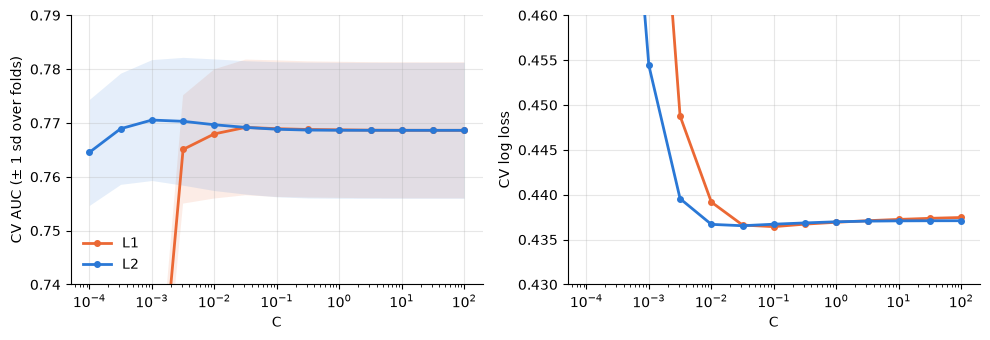

In [10]:
import matplotlib.pyplot as plt

colours = {"L2": "#2a78d6", "L1": "#eb6834"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
for penalty, d in cv_res.groupby("penalty"):
    ax1.plot(d["C"], d["auc"], "o-", color=colours[penalty], lw=2, ms=4, label=penalty)
    ax1.fill_between(d["C"], d["auc"] - d["auc_sd"], d["auc"] + d["auc_sd"],
                     color=colours[penalty], alpha=0.12, lw=0)
    ax2.plot(d["C"], d["logloss"], "o-", color=colours[penalty], lw=2, ms=4, label=penalty)
ax1.set(xscale="log", xlabel="C", ylabel="CV AUC (± 1 sd over folds)", ylim=(0.74, 0.79))
ax2.set(xscale="log", xlabel="C", ylabel="CV log loss", ylim=(0.43, 0.46))
for ax in (ax1, ax2):
    ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax1.legend(frameon=False)
plt.tight_layout()

Pick best C per penalty by CV log loss, refit on all of train, check on validation.

In [11]:
best = cv_res.loc[cv_res.groupby("penalty")["logloss"].idxmin()]
print(best.round(4).to_string(index=False), "\n")

models = {}
for _, row in best.iterrows():
    l1_ratio = 1 if row["penalty"] == "L1" else 0
    m = LogisticRegression(C=row["C"], l1_ratio=l1_ratio, solver="liblinear", max_iter=1000)
    m.fit(X_train, y_train)
    models[row["penalty"]] = m
    score(f"{row['penalty']} C={row['C']:.3g}", m.predict_proba(X_val)[:, 1])

# which features did L1 drop?
coefs = pd.Series(models["L1"].coef_[0], index=X_train.columns)
print(f"\nL1 kept {(coefs != 0).sum()} of {len(coefs)}; dropped:", list(coefs[coefs == 0].index))

penalty      C    auc  auc_sd  logloss
     L1 0.1000 0.7689  0.0127   0.4364
     L2 0.0316 0.7692  0.0124   0.4365 

L1 C=0.1               AUC 0.7782   log loss 0.4285   acc 0.8255
L2 C=0.0316            AUC 0.7783   log loss 0.4284   acc 0.8251

L1 kept 44 of 50; dropped: ['BILL_AMT2', 'PAY_5_-2', 'PAY_5_0', 'PAY_5_1', 'PAY_6_0', 'PAY_6_1']
